<a href="https://colab.research.google.com/github/MoRe-25/ML-FA/blob/main/Bank_Telemarketing_Research_Replication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

from google.colab import files

uploaded = files.upload()


Saving archive.zip to archive (1).zip


In [ ]:

import zipfile
import os

zip_path = next(
    name for name in uploaded
    if name.lower().endswith(".zip")
)

extract_path = "/content/bank_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

for root, dirs, filenames in os.walk(extract_path):
    for filename in filenames:
        print(os.path.join(root, filename))


/content/bank_dataset/bank-full.csv
/content/bank_dataset/bank_cleaned.csv


In [ ]:

import os

for root, dirs, filenames in os.walk("/content/bank_dataset"):
    for filename in filenames:
        print(filename)


bank-full.csv
bank_cleaned.csv


In [ ]:

import pandas as pd
import os

data_path = "/content/bank_dataset"

# Load both datasets
bank_full = pd.read_csv(
    os.path.join(data_path, "bank-full.csv"),
    sep=None,
    engine="python"
)

bank_cleaned = pd.read_csv(
    os.path.join(data_path, "bank_cleaned.csv"),
    sep=None,
    engine="python"
)

# Display dataset dimensions
print("BANK-FULL DATASET")
print("Shape:", bank_full.shape)
print("Columns:", list(bank_full.columns))

print("\nBANK-CLEANED DATASET")
print("Shape:", bank_cleaned.shape)
print("Columns:", list(bank_cleaned.columns))

# Display first five records
print("\nFirst 5 records of bank-full:")
display(bank_full.head())

print("\nFirst 5 records of bank_cleaned:")
display(bank_cleaned.head())


BANK-FULL DATASET
Shape: (45211, 17)
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

BANK-CLEANED DATASET
Shape: (40841, 18)
Columns: ['Unnamed: 0', 'age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'response', 'response_binary']

First 5 records of bank-full:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no



First 5 records of bank_cleaned:


,Unnamed: 0,age,job,marital,education,default,balance,housing,loan,day,month,duration,campaign,pdays,previous,poutcome,response,response_binary
0,0,58,management,married,tertiary,no,2143,yes,no,5,may,4.35,1,-1,0,unknown,no,0
1,1,44,technician,single,secondary,no,29,yes,no,5,may,2.52,1,-1,0,unknown,no,0
2,2,33,entrepreneur,married,secondary,no,2,yes,yes,5,may,1.27,1,-1,0,unknown,no,0
3,5,35,management,married,tertiary,no,231,yes,no,5,may,2.32,1,-1,0,unknown,no,0
4,6,28,management,single,tertiary,no,447,yes,yes,5,may,3.62,1,-1,0,unknown,no,0


In [ ]:

# DATASET AUDIT

print("=" * 55)
print("1. MISSING VALUES")
print("=" * 55)

print("\nBank-full:")
print(bank_full.isnull().sum())

print("\nBank-cleaned:")
print(bank_cleaned.isnull().sum())


print("\n" + "=" * 55)
print("2. TARGET DISTRIBUTION")
print("=" * 55)

print("\nBank-full (y):")
print(bank_full["y"].value_counts(dropna=False))
print("\nPercentages:")
print(bank_full["y"].value_counts(normalize=True) * 100)

print("\nBank-cleaned (response):")
print(bank_cleaned["response"].value_counts(dropna=False))
print("\nBinary target:")
print(bank_cleaned["response_binary"].value_counts(dropna=False))


print("\n" + "=" * 55)
print("3. DUPLICATE RECORDS")
print("=" * 55)

print("Bank-full duplicates:", bank_full.duplicated().sum())

clean_features = bank_cleaned.drop(
    columns=["Unnamed: 0"], errors="ignore"
)
print("Bank-cleaned duplicates:", clean_features.duplicated().sum())


print("\n" + "=" * 55)
print("4. CLEANED DATASET INDEX")
print("=" * 55)

print("First 20 original indices:")
print(bank_cleaned["Unnamed: 0"].head(20).tolist())

print("\nLast 10 original indices:")
print(bank_cleaned["Unnamed: 0"].tail(10).tolist())


print("\n" + "=" * 55)
print("5. DURATION CHECK")
print("=" * 55)

print("Original duration statistics (seconds):")
print(bank_full["duration"].describe())

print("\nCleaned duration statistics (minutes):")
print(bank_cleaned["duration"].describe())


print("\n" + "=" * 55)
print("6. CATEGORICAL VALUES")
print("=" * 55)

for col in ["job", "education", "contact", "poutcome"]:
    if col in bank_full.columns:
        print(f"\n{col}:")
        print(bank_full[col].value_counts(dropna=False))


1. MISSING VALUES

Bank-full:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Bank-cleaned:
Unnamed: 0         0
age                0
job                0
marital            0
education          0
default            0
balance            0
housing            0
loan               0
day                0
month              0
duration           0
campaign           0
pdays              0
previous           0
poutcome           0
response           0
response_binary    0
dtype: int64

2. TARGET DISTRIBUTION

Bank-full (y):
y
no     39922
yes     5289
Name: count, dtype: int64

Percentages:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64

Bank-cleaned (response):
response
no     36202
yes     4639
Name: count, dtype: int64

Binary target:
response_binary
0 

In [ ]:

# INVESTIGATE HOW THE CLEANED DATASET DIFFERS

print("=" * 55)
print("1. ORIGINAL ROWS MISSING FROM CLEANED DATA")
print("=" * 55)

original_indices = set(range(len(bank_full)))
cleaned_indices = set(bank_cleaned["Unnamed: 0"].astype(int))

removed_indices = sorted(original_indices - cleaned_indices)

print("Rows removed:", len(removed_indices))
print("First 30 removed indices:", removed_indices[:30])

print("\nTarget distribution of removed rows:")
print(bank_full.iloc[removed_indices]["y"].value_counts())

print("\nTarget percentages of removed rows:")
print(
    bank_full.iloc[removed_indices]["y"]
    .value_counts(normalize=True) * 100
)


print("\n" + "=" * 55)
print("2. CHECK BINARY TARGET CONSISTENCY")
print("=" * 55)

expected_binary = bank_cleaned["response"].map(
    {"no": 0, "yes": 1}
)

print(
    "Mismatches between response and response_binary:",
    (expected_binary != bank_cleaned["response_binary"]).sum()
)


print("\n" + "=" * 55)
print("3. CHECK DURATION CONVERSION")
print("=" * 55)

original_duration = bank_full.loc[
    bank_cleaned["Unnamed: 0"].astype(int),
    "duration"
].reset_index(drop=True)

converted_duration = original_duration / 60

difference = (
    converted_duration - bank_cleaned["duration"]
).abs()

print("Maximum absolute difference in minutes:", difference.max())
print("Exact conversion match:", difference.max() < 0.000001)


print("\n" + "=" * 55)
print("4. CHECK WHETHER CONTACT WAS REMOVED")
print("=" * 55)

# Restore the original rows using the saved index
restored = bank_full.iloc[
    bank_cleaned["Unnamed: 0"].astype(int)
].reset_index(drop=True)

print("Contact distribution among retained rows:")
print(restored["contact"].value_counts())

print("\nContact distribution among removed rows:")
print(bank_full.iloc[removed_indices]["contact"].value_counts())


1. ORIGINAL ROWS MISSING FROM CLEANED DATA
Rows removed: 4370
First 30 removed indices: [3, 4, 13, 16, 34, 42, 44, 57, 58, 64, 69, 93, 120, 122, 130, 137, 150, 156, 160, 172, 186, 203, 208, 216, 217, 224, 226, 228, 233, 241]

Target distribution of removed rows:
y
no     3720
yes     650
Name: count, dtype: int64

Target percentages of removed rows:
y
no     85.125858
yes    14.874142
Name: proportion, dtype: float64

2. CHECK BINARY TARGET CONSISTENCY
Mismatches between response and response_binary: 0

3. CHECK DURATION CONVERSION
Maximum absolute difference in minutes: 0.003333333333337407
Exact conversion match: False

4. CHECK WHETHER CONTACT WAS REMOVED
Contact distribution among retained rows:
contact
cellular     26240
unknown      12115
telephone     2486
Name: count, dtype: int64

Contact distribution among removed rows:
contact
cellular     3045
unknown       905
telephone     420
Name: count, dtype: int64


In [ ]:

# INVESTIGATE THE FILTERING RULE

removed = bank_full.iloc[removed_indices].copy()
retained = bank_full.drop(index=removed_indices).copy()

print("=" * 55)
print("1. NUMERICAL FEATURE COMPARISON")
print("=" * 55)

numeric_cols = [
    "age", "balance", "duration",
    "campaign", "pdays", "previous"
]

print("\nRemoved records:")
display(removed[numeric_cols].describe().round(2))

print("\nRetained records:")
display(retained[numeric_cols].describe().round(2))


print("\n" + "=" * 55)
print("2. CATEGORICAL DISTRIBUTIONS IN REMOVED ROWS")
print("=" * 55)

for col in ["job", "marital", "education", "default",
            "housing", "loan", "poutcome", "month"]:
    print(f"\n{col}:")
    print(removed[col].value_counts(normalize=True).mul(100).round(2))


print("\n" + "=" * 55)
print("3. DURATION CONVERSION DETAILS")
print("=" * 55)

original_duration = bank_full.loc[
    bank_cleaned["Unnamed: 0"].astype(int), "duration"
].reset_index(drop=True)

exact_minutes = original_duration / 60
clean_minutes = bank_cleaned["duration"].reset_index(drop=True)

print("Original seconds divisible by 60:",
      (original_duration % 60 == 0).sum())

print("Cleaned duration decimal places:")
print(clean_minutes.astype(str).str.split(".").str[-1].str.len()
      .value_counts().sort_index())

print("\nFirst 10 original vs cleaned durations:")
display(pd.DataFrame({
    "original_seconds": original_duration.head(10),
    "exact_minutes": exact_minutes.head(10),
    "cleaned_minutes": clean_minutes.head(10)
}))


print("\n" + "=" * 55)
print("4. POSSIBLE FILTERING CONDITIONS")
print("=" * 55)

print("Removed rows with duration = 0:",
      (removed["duration"] == 0).sum())

print("Removed rows with duration < 60 seconds:",
      (removed["duration"] < 60).sum())

print("Removed rows with unknown job:",
      (removed["job"] == "unknown").sum())

print("Removed rows with unknown education:",
      (removed["education"] == "unknown").sum())

print("Removed rows with unknown poutcome:",
      (removed["poutcome"] == "unknown").sum())



1. NUMERICAL FEATURE COMPARISON

Removed records:


,age,balance,duration,campaign,pdays,previous
count,4370.00,4370.00,4370.00,4370.00,4370.00,4370.00
mean,42.30,4056.57,254.68,2.67,114.49,1.92
std,11.79,7776.77,249.73,3.04,143.77,5.46
min,18.00,-8019.00,0.00,1.00,-1.00,0.00
25%,33.00,180.25,98.00,1.00,-1.00,0.00
50%,41.00,803.00,178.00,2.00,2.00,1.00
75%,51.00,3537.00,325.75,3.00,208.75,2.00
max,93.00,102127.00,2429.00,63.00,838.00,275.00



Retained records:


,age,balance,duration,campaign,pdays,previous
count,40841.00,40841.00,40841.00,40841.00,40841.00,40841.00
mean,40.79,1073.98,258.54,2.77,32.25,0.44
std,10.48,1712.56,258.35,3.10,90.74,1.57
min,18.00,-6847.00,6.00,1.00,-1.00,0.00
25%,33.00,64.00,104.00,1.00,-1.00,0.00
50%,39.00,421.00,180.00,2.00,-1.00,0.00
75%,48.00,1333.00,318.00,3.00,-1.00,0.00
max,95.00,10443.00,4918.00,58.00,871.00,55.00



2. CATEGORICAL DISTRIBUTIONS IN REMOVED ROWS

job:
job
blue-collar      21.21
management       20.43
technician       14.71
admin.           10.66
services          8.08
student           5.70
retired           5.58
entrepreneur      3.36
self-employed     3.11
unknown           2.97
unemployed        2.08
housemaid         2.08
Name: proportion, dtype: float64

marital:
marital
married     58.88
single      30.82
divorced    10.30
Name: proportion, dtype: float64

education:
education
unknown      42.49
secondary    29.04
tertiary     21.08
primary       7.39
Name: proportion, dtype: float64

default:
default
no     98.81
yes     1.19
Name: proportion, dtype: float64

housing:
housing
yes    52.86
no     47.14
Name: proportion, dtype: float64

loan:
loan
no     89.82
yes    10.18
Name: proportion, dtype: float64

poutcome:
poutcome
unknown    49.36
other      42.11
failure     5.79
success     2.75
Name: proportion, dtype: float64

month:
month
may    29.06
jun    11.17
nov    11.14


,original_seconds,exact_minutes,cleaned_minutes
0,261,4.350000,4.35
1,151,2.516667,2.52
2,76,1.266667,1.27
3,139,2.316667,2.32
4,217,3.616667,3.62
5,380,6.333333,6.33
6,50,0.833333,0.83
7,55,0.916667,0.92
8,222,3.700000,3.70
9,137,2.283333,2.28



4. POSSIBLE FILTERING CONDITIONS
Removed rows with duration = 0: 3
Removed rows with duration < 60 seconds: 593
Removed rows with unknown job: 130
Removed rows with unknown education: 1857
Removed rows with unknown poutcome: 2157


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Copy the original-format dataset
df = bank_full.copy()

# Separate target from input features
y = df["y"].map({"no": 0, "yes": 1})

# Exclude target and current-call duration
X = df.drop(columns=["y", "duration"])

# Identify column types
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

print("\nCategorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nTarget distribution:")
print(y.value_counts())


Dataset shape: (45211, 15)
Target shape: (45211,)

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Numerical features:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Target distribution:
y
0    39922
1     5289
Name: count, dtype: int64


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).mul(100).round(2))


# Preprocessing for numerical features
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("\nPreprocessing pipeline created successfully.")


Training records: 36168
Testing records: 9043

Training target distribution:
y
0    88.3
1    11.7
Name: proportion, dtype: float64

Testing target distribution:
y
0    88.3
1    11.7
Name: proportion, dtype: float64

Preprocessing pipeline created successfully.


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Create the complete model pipeline
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Train the model
lr_model.fit(X_train, y_train)

# Generate predictions
y_pred = lr_model.predict(X_test)
y_prob = lr_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("LOGISTIC REGRESSION RESULTS")
print("=" * 40)

print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No subscription", "Subscription"]
))


LOGISTIC REGRESSION RESULTS
Accuracy:  0.8933
Precision: 0.6632
Recall:    0.1786
F1-score:  0.2815
ROC-AUC:   0.7717

Confusion Matrix:
[[7889   96]
 [ 869  189]]

Classification Report:
                 precision    recall  f1-score   support

No subscription       0.90      0.99      0.94      7985
   Subscription       0.66      0.18      0.28      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.58      0.61      9043
   weighted avg       0.87      0.89      0.87      9043



In [ ]:

from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree pipeline
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(
        max_depth=8,
        min_samples_leaf=20,
        random_state=42
    ))
])

# Train the model
dt_model.fit(X_train, y_train)

# Predictions
dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

# Evaluate
print("DECISION TREE RESULTS")
print("=" * 40)

print(f"Accuracy:  {accuracy_score(y_test, dt_pred):.4f}")
print(f"Precision: {precision_score(y_test, dt_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, dt_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, dt_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, dt_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_pred,
    target_names=["No subscription", "Subscription"]
))


DECISION TREE RESULTS
Accuracy:  0.8932
Precision: 0.6329
Recall:    0.2070
F1-score:  0.3120
ROC-AUC:   0.7248

Confusion Matrix:
[[7858  127]
 [ 839  219]]

Classification Report:
                 precision    recall  f1-score   support

No subscription       0.90      0.98      0.94      7985
   Subscription       0.63      0.21      0.31      1058

       accuracy                           0.89      9043
      macro avg       0.77      0.60      0.63      9043
   weighted avg       0.87      0.89      0.87      9043



In [ ]:

from sklearn.neural_network import MLPClassifier

# Create Neural Network pipeline
nn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", MLPClassifier(
        hidden_layer_sizes=(6,),
        activation="relu",
        solver="adam",
        max_iter=300,
        early_stopping=True,
        random_state=42
    ))
])

# Train the model
nn_model.fit(X_train, y_train)

# Predictions
nn_pred = nn_model.predict(X_test)
nn_prob = nn_model.predict_proba(X_test)[:, 1]

# Evaluate
print("NEURAL NETWORK RESULTS")
print("=" * 40)

print(f"Accuracy:  {accuracy_score(y_test, nn_pred):.4f}")
print(f"Precision: {precision_score(y_test, nn_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, nn_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, nn_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, nn_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nn_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    nn_pred,
    target_names=["No subscription", "Subscription"]
))


NEURAL NETWORK RESULTS
Accuracy:  0.8938
Precision: 0.6655
Recall:    0.1862
F1-score:  0.2910
ROC-AUC:   0.7829

Confusion Matrix:
[[7886   99]
 [ 861  197]]

Classification Report:
                 precision    recall  f1-score   support

No subscription       0.90      0.99      0.94      7985
   Subscription       0.67      0.19      0.29      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.59      0.62      9043
   weighted avg       0.87      0.89      0.87      9043



In [ ]:
#did not run
from sklearn.svm import SVC

# Create SVM pipeline
svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        probability=True,
        random_state=42
    ))
])

# Train the model
print("Training SVM... Please wait.")
svm_model.fit(X_train, y_train)

# Predictions
svm_pred = svm_model.predict(X_test)
svm_prob = svm_model.predict_proba(X_test)[:, 1]

# Evaluate
print("\nSVM RESULTS")
print("=" * 40)

print(f"Accuracy:  {accuracy_score(y_test, svm_pred):.4f}")
print(f"Precision: {precision_score(y_test, svm_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, svm_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, svm_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, svm_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    svm_pred,
    target_names=["No subscription", "Subscription"]
))


In [ ]:
#using the LinerSVC model instead
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

svm_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LinearSVC(
        C=1.0,
        max_iter=5000,
        random_state=42
    ))
])

print("Training Linear SVM...")
svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)
svm_scores = svm_model.decision_function(X_test)

print("\nLINEAR SVM RESULTS")
print("=" * 40)
print(f"Accuracy:  {accuracy_score(y_test, svm_pred):.4f}")
print(f"Precision: {precision_score(y_test, svm_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, svm_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, svm_pred, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, svm_scores):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

print("\nClassification Report:")
print(classification_report(
    y_test, svm_pred,
    target_names=["No subscription", "Subscription"]
))


Training Linear SVM...

LINEAR SVM RESULTS
Accuracy:  0.8932
Precision: 0.6513
Recall:    0.1871
F1-score:  0.2907
ROC-AUC:   0.7682

Confusion Matrix:
[[7879  106]
 [ 860  198]]

Classification Report:
                 precision    recall  f1-score   support

No subscription       0.90      0.99      0.94      7985
   Subscription       0.65      0.19      0.29      1058

       accuracy                           0.89      9043
      macro avg       0.78      0.59      0.62      9043
   weighted avg       0.87      0.89      0.87      9043



In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score

def cumulative_lift_auc(y_true, scores):
    # Sort customers from highest to lowest predicted score
    order = np.argsort(-np.asarray(scores))
    y_sorted = np.asarray(y_true)[order]

    total_positives = y_sorted.sum()
    if total_positives == 0:
        return np.nan

    # Cumulative fraction of actual subscribers captured
    cumulative_positives = np.cumsum(y_sorted) / total_positives

    # Fraction of customers contacted
    population_fraction = np.arange(1, len(y_sorted) + 1) / len(y_sorted)

    # Area under the cumulative gains curve
    return np.trapezoid(
        np.r_[0, cumulative_positives],
        np.r_[0, population_fraction]
    )

# Scores for all four models
model_scores = {
    "Logistic Regression": lr_model.predict_proba(X_test)[:, 1],
    "Decision Tree": dt_model.predict_proba(X_test)[:, 1],
    "Neural Network": nn_model.predict_proba(X_test)[:, 1],
    "Linear SVM": svm_model.decision_function(X_test)
}

results = []

for name, scores in model_scores.items():
    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Cumulative Gains AUC": cumulative_lift_auc(y_test, scores)
    })

results_df = pd.DataFrame(results).sort_values(
    by="ROC-AUC", ascending=False
)

print(results_df.to_string(index=False))


              Model  ROC-AUC  Cumulative Gains AUC
     Neural Network 0.782882              0.749785
Logistic Regression 0.771749              0.739955
         Linear SVM 0.768213              0.736833
      Decision Tree 0.724840              0.698537


In [ ]:
# Check which trained model variables are available
for name, obj in globals().copy().items():
    if any(word in name.lower() for word in
           ["log", "tree", "neural", "mlp", "svm", "model", "pipe"]):
        if hasattr(obj, "predict") and hasattr(obj, "fit"):
            print(name, ":", type(obj).__name__)

Pipeline : ABCMeta
LogisticRegression : type
lr_model : Pipeline
DecisionTreeClassifier : ABCMeta
dt_model : Pipeline
MLPClassifier : ABCMeta
nn_model : Pipeline
svm_model : Pipeline


In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score

models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Neural Network": nn_model,
    "Linear SVM": svm_model
}

def decile_gains_area(y_true, scores, n_deciles=10):
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    # Sort observations by predicted score, highest first
    order = np.argsort(-scores)
    y_sorted = y_true[order]

    total = len(y_sorted)
    total_positives = y_sorted.sum()

    if total_positives == 0:
        return np.nan

    # Divide the ranked observations into 10 approximately equal groups
    decile_results = []

    for i in range(1, n_deciles + 1):
        end = int(np.ceil(i * total / n_deciles))
        positives_captured = y_sorted[:end].sum()

        decile_results.append({
            "Population contacted (%)": 100 * end / total,
            "Positive responses captured (%)":
                100 * positives_captured / total_positives
        })

    gains_df = pd.DataFrame(decile_results)

    # Include the origin and calculate area under the cumulative gains curve
    x = np.r_[0, gains_df["Population contacted (%)"].to_numpy() / 100]
    y = np.r_[0, gains_df["Positive responses captured (%)"].to_numpy() / 100]

    area = np.trapezoid(y, x)

    return area, gains_df


results = []
gains_curves = {}

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)

    area, gains_df = decile_gains_area(y_test, scores)
    gains_curves[name] = gains_df

    results.append({
        "Model": name,
        "ROC-AUC": roc_auc_score(y_test, scores),
        "Decile Gains Area (our implementation)": area
    })

gains_comparison = pd.DataFrame(results)
print(gains_comparison.round(4).to_string(index=False))

              Model  ROC-AUC  Decile Gains Area (our implementation)
Logistic Regression   0.7717                                  0.7353
      Decision Tree   0.7248                                  0.6948
     Neural Network   0.7829                                  0.7458
         Linear SVM   0.7682                                  0.7318


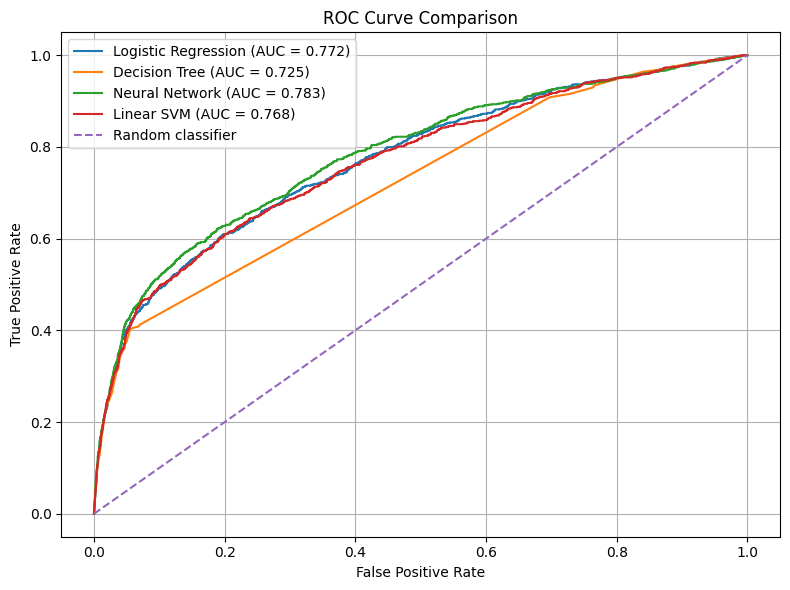

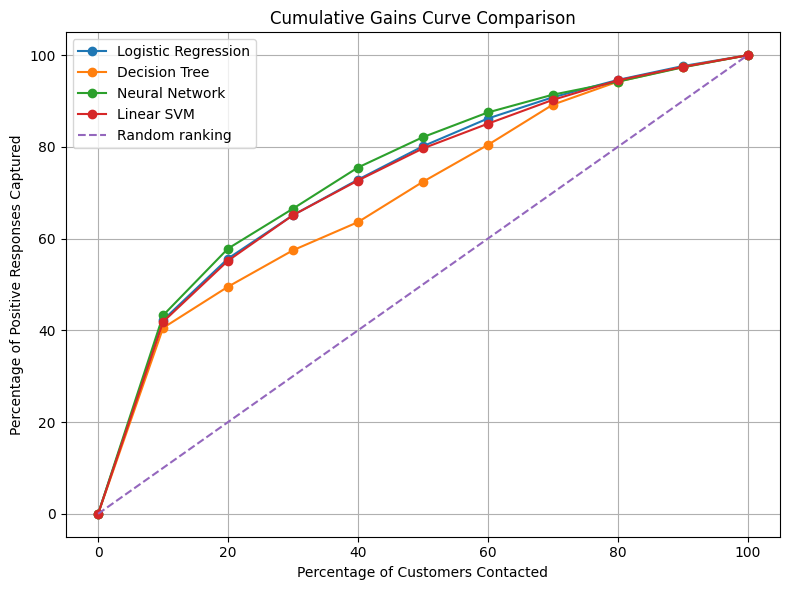

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

from sklearn.metrics import roc_curve, roc_auc_score

# Store scores for each model
model_scores = {}

for name, model in models.items():
    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
    else:
        scores = model.decision_function(X_test)

    model_scores[name] = scores


# Plot 1: ROC curves
plt.figure(figsize=(8, 6))

for name, scores in model_scores.items():
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc = roc_auc_score(y_test, scores)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# Plot 2: Cumulative gains curves
plt.figure(figsize=(8, 6))

for name, scores in model_scores.items():
    gains_df = gains_curves[name]

    x = np.r_[
        0,
        gains_df["Population contacted (%)"].to_numpy()
    ]
    y = np.r_[
        0,
        gains_df["Positive responses captured (%)"].to_numpy()
    ]

    plt.plot(x, y, marker="o", label=name)

# Random-ranking baseline
plt.plot([0, 100], [0, 100], linestyle="--", label="Random ranking")

plt.xlabel("Percentage of Customers Contacted")
plt.ylabel("Percentage of Positive Responses Captured")
plt.title("Cumulative Gains Curve Comparison")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# **We now use the original rolling window approach**

The reason we didnt do this before is because the dataset provided in the excel sheet to us did not contain year, it only had month and day mentioned. So we are making our own time duration of years and implementing a sample rolling window for it

In [ ]:
import pandas as pd

df_check = pd.read_csv(
    "/content/bank_dataset/bank-full.csv",
    sep=";"
)

month_order = {
    "jan": 1, "feb": 2, "mar": 3,
    "apr": 4, "may": 5, "jun": 6,
    "jul": 7, "aug": 8, "sep": 9,
    "oct": 10, "nov": 11, "dec": 12
}

df_check["month_num"] = (
    df_check["month"].str.lower().map(month_order)
)

print("First 15 records:")
print(df_check[["month", "day", "y"]].head(15))

print("\nLast 15 records:")
print(df_check[["month", "day", "y"]].tail(15))

print("\nMonth order in first 30 records:")
print(df_check["month"].head(30).tolist())

print("\nMonth order in last 30 records:")
print(df_check["month"].tail(30).tolist())

First 15 records:
   month  day   y
0    may    5  no
1    may    5  no
2    may    5  no
3    may    5  no
4    may    5  no
5    may    5  no
6    may    5  no
7    may    5  no
8    may    5  no
9    may    5  no
10   may    5  no
11   may    5  no
12   may    5  no
13   may    5  no
14   may    5  no

Last 15 records:
      month  day    y
45196   nov   16  yes
45197   nov   16  yes
45198   nov   16   no
45199   nov   16   no
45200   nov   16  yes
45201   nov   17  yes
45202   nov   17  yes
45203   nov   17  yes
45204   nov   17  yes
45205   nov   17  yes
45206   nov   17  yes
45207   nov   17  yes
45208   nov   17  yes
45209   nov   17   no
45210   nov   17   no

Month order in first 30 records:
['may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may', 'may']

Month order in last 30 records:
['nov', 'nov', 'nov', 'nov', 'nov', 'nov', 'no

In [ ]:
import pandas as pd

df_check = pd.read_csv(
    "/content/bank_dataset/bank-full.csv",
    sep=";"
)

month_order = {
    "jan": 1, "feb": 2, "mar": 3, "apr": 4,
    "may": 5, "jun": 6, "jul": 7, "aug": 8,
    "sep": 9, "oct": 10, "nov": 11, "dec": 12
}

month_num = df_check["month"].str.lower().map(month_order)

# Convert month and day to a sortable month/day key.
# This checks broad ordering only, not full calendar dates.
date_key = month_num * 100 + df_check["day"]

print("Number of rows:", len(df_check))
print("Month transitions:")
print(
    df_check.loc[
        df_check["month"].ne(df_check["month"].shift()),
        ["month", "day"]
    ].head(30)
)

print("\nRows where month/day order moves backward:")
backward = date_key.diff().lt(0)
print("Count:", int(backward.sum()))
print(df_check.loc[backward, ["month", "day"]].head(20))

print("\nMonth counts:")
print(df_check["month"].value_counts().reindex(
    ["jan", "feb", "mar", "apr", "may", "jun",
     "jul", "aug", "sep", "oct", "nov", "dec"]
).dropna())

Number of rows: 45211
Month transitions:
      month  day
0       may    5
7957    jun    2
12443   jul    1
18823   aug    4
24038   oct   17
24118   nov    4
27716   dec    4
27729   jan   28
28905   feb    2
31201   mar    2
31459   apr    1
34177   may    4
39752   jun    1
40394   jul    1
40601   aug    4
41373   sep    1
41655   oct    1
42093   nov    2
42390   dec    2
42591   jan    6
42818   feb    1
43171   mar    1
43390   apr    1
43604   may    4
43838   jun    1
44051   jul    1
44359   aug    1
44619   sep    1
44916   oct    1
45136   nov    2

Rows where month/day order moves backward:
Count: 2
      month  day
27729   jan   28
42591   jan    6

Month counts:
month
jan     1403
feb     2649
mar      477
apr     2932
may    13766
jun     5341
jul     6895
aug     6247
sep      579
oct      738
nov     3970
dec      214
Name: count, dtype: int64


In [ ]:
# Inspect records around the two apparent backward transitions

for idx in [27729, 42591]:
    print(f"\n--- Rows around index {idx} ---")
    print(
        df_check.loc[
            idx - 5:idx + 5,
            ["month", "day", "campaign", "pdays", "previous", "y"]
        ]
    )


--- Rows around index 27729 ---
      month  day  campaign  pdays  previous    y
27724   dec   11         1     -1         0   no
27725   dec   12         1     -1         0   no
27726   dec   13         1     -1         0   no
27727   dec   22         1     -1         0  yes
27728   dec   27         1     -1         0   no
27729   jan   28         1    268         1   no
27730   jan   28         1    268         2   no
27731   jan   28         1     -1         0   no
27732   jan   28         1     -1         0   no
27733   jan   28         1     -1         0   no
27734   jan   28         1     -1         0   no

--- Rows around index 42591 ---
      month  day  campaign  pdays  previous    y
42586   dec   30         2    218         1   no
42587   dec   30         2     -1         0  yes
42588   dec   30         3     -1         0   no
42589   dec   30         3    232         2   no
42590   dec   31         3    198         2   no
42591   jan    6         1     -1         0   no
425

In [ ]:
print("Shape:", df_check.shape)
print("Columns:", df_check.columns.tolist())

print("\nFirst and last rows:")
print(df_check.iloc[[0, -1]][["month", "day", "y"]])

print("\nMonth/day transition counts:")
print(
    df_check.assign(
        month_num=df_check["month"].str.lower().map(month_order)
    )["month_num"].diff().value_counts().sort_index()
)

Shape: (45211, 17)
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

First and last rows:
      month  day   y
0       may    5  no
45210   nov   17  no

Month/day transition counts:
month_num
-11.0        2
 0.0     45181
 1.0        26
 2.0         1
Name: count, dtype: int64


In [ ]:
import pandas as pd

# Load the primary dataset
df = pd.read_csv(
    "/content/bank_dataset/bank-full.csv",
    sep=";"
)

# Rolling-window configuration
initial_train_size = 20000
test_window_size = 2500
step_size = 2500

n = len(df)
rolling_windows = []

train_end = initial_train_size
window_number = 1

while train_end + test_window_size <= n:
    test_start = train_end
    test_end = test_start + test_window_size

    rolling_windows.append({
        "Window": window_number,
        "Train Start": 0,
        "Train End (exclusive)": train_end,
        "Test Start": test_start,
        "Test End (exclusive)": test_end,
        "Training Records": train_end,
        "Testing Records": test_end - test_start
    })

    train_end += step_size
    window_number += 1

# Include the final partial test window, if any records remain
if train_end < n:
    rolling_windows.append({
        "Window": window_number,
        "Train Start": 0,
        "Train End (exclusive)": train_end,
        "Test Start": train_end,
        "Test End (exclusive)": n,
        "Training Records": train_end,
        "Testing Records": n - train_end
    })

window_table = pd.DataFrame(rolling_windows)

print("Total records:", n)
print("Number of rolling windows:", len(window_table))
print("\nWindow schedule:")
print(window_table.to_string(index=False))

Total records: 45211
Number of rolling windows: 11

Window schedule:
 Window  Train Start  Train End (exclusive)  Test Start  Test End (exclusive)  Training Records  Testing Records
      1            0                  20000       20000                 22500             20000             2500
      2            0                  22500       22500                 25000             22500             2500
      3            0                  25000       25000                 27500             25000             2500
      4            0                  27500       27500                 30000             27500             2500
      5            0                  30000       30000                 32500             30000             2500
      6            0                  32500       32500                 35000             32500             2500
      7            0                  35000       35000                 37500             35000             2500
      8            0       

In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/bank_dataset/bank-full.csv",
    sep=";"
)

y = df["y"].map({"no": 0, "yes": 1})

distribution_results = []

for window in rolling_windows:
    train_start = window["Train Start"]
    train_end = window["Train End (exclusive)"]
    test_start = window["Test Start"]
    test_end = window["Test End (exclusive)"]

    y_train_window = y.iloc[train_start:train_end]
    y_test_window = y.iloc[test_start:test_end]

    distribution_results.append({
        "Window": window["Window"],
        "Train N": len(y_train_window),
        "Train Positives": int(y_train_window.sum()),
        "Train Positive %": round(y_train_window.mean() * 100, 2),
        "Test N": len(y_test_window),
        "Test Positives": int(y_test_window.sum()),
        "Test Positive %": round(y_test_window.mean() * 100, 2),
        "Test Classes": y_test_window.nunique()
    })

distribution_df = pd.DataFrame(distribution_results)

print(distribution_df.to_string(index=False))

 Window  Train N  Train Positives  Train Positive %  Test N  Test Positives  Test Positive %  Test Classes
      1    20000              926              4.63    2500             161             6.44             2
      2    22500             1087              4.83    2500             153             6.12             2
      3    25000             1240              4.96    2500             146             5.84             2
      4    27500             1386              5.04    2500             134             5.36             2
      5    30000             1520              5.07    2500             446            17.84             2
      6    32500             1966              6.05    2500             396            15.84             2
      7    35000             2362              6.75    2500             173             6.92             2
      8    37500             2535              6.76    2500             361            14.44             2
      9    40000             2896    

# **Expanding rolling window**

In [ ]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC

# Reload data and prepare features
df = pd.read_csv(
    "/content/bank_dataset/bank-full.csv",
    sep=";"
)

y = df["y"].map({"no": 0, "yes": 1})
X = df.drop(columns=["y", "duration"])

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

# Recreate preprocessing components
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.pipeline import Pipeline as SkPipeline

numerical_pipeline = SkPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = SkPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

def make_models():
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=2000, random_state=42
        ),
        "Decision Tree": DecisionTreeClassifier(
            max_depth=8,
            min_samples_leaf=20,
            random_state=42
        ),
        "Neural Network": MLPClassifier(
            hidden_layer_sizes=(6,),
            activation="relu",
            solver="adam",
            max_iter=300,
            early_stopping=True,
            random_state=42
        ),
        "Linear SVM": LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=42
        )
    }

rolling_results = []

for window in rolling_windows:
    train_start = window["Train Start"]
    train_end = window["Train End (exclusive)"]
    test_start = window["Test Start"]
    test_end = window["Test End (exclusive)"]

    X_train_w = X.iloc[train_start:train_end]
    y_train_w = y.iloc[train_start:train_end]
    X_test_w = X.iloc[test_start:test_end]
    y_test_w = y.iloc[test_start:test_end]

    for model_name, classifier in make_models().items():
        model = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("classifier", classifier)
        ])

        model.fit(X_train_w, y_train_w)
        predictions = model.predict(X_test_w)

        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_test_w)[:, 1]
        else:
            scores = model.decision_function(X_test_w)

        auc = (
            roc_auc_score(y_test_w, scores)
            if y_test_w.nunique() == 2
            else np.nan
        )

        rolling_results.append({
            "Window": window["Window"],
            "Model": model_name,
            "Train N": len(X_train_w),
            "Test N": len(X_test_w),
            "Test Positive %": round(y_test_w.mean() * 100, 2),
            "Accuracy": accuracy_score(y_test_w, predictions),
            "Precision": precision_score(
                y_test_w, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test_w, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_test_w, predictions, zero_division=0
            ),
            "ROC-AUC": auc
        })

rolling_results_df = pd.DataFrame(rolling_results)

print("Rolling-window evaluation completed.")
print("Total model evaluations:", len(rolling_results_df))

print("\nROC-AUC by window and model:")
print(
    rolling_results_df.pivot(
        index="Window",
        columns="Model",
        values="ROC-AUC"
    ).round(4).to_string()
)

Rolling-window evaluation completed.
Total model evaluations: 44

ROC-AUC by window and model:
Model   Decision Tree  Linear SVM  Logistic Regression  Neural Network
Window                                                                
1              0.5454      0.5261               0.5270          0.5273
2              0.4441      0.5378               0.4436          0.3713
3              0.5348      0.5796               0.5793          0.5080
4              0.5918      0.6111               0.6351          0.4659
5              0.5477      0.6252               0.6010          0.4702
6              0.6559      0.6922               0.6907          0.5026
7              0.5407      0.6127               0.6074          0.5610
8              0.5847      0.6671               0.6753          0.5686
9              0.5484      0.5750               0.5680          0.5823
10             0.6511      0.6535               0.6633          0.6728
11             0.6957      0.6957               0.690

# **Static rolling window**

In [ ]:

import pandas as pd

df = pd.read_csv(
    "/content/bank_dataset/bank-full.csv",
    sep=";"
)

# Parameters from the original paper
W = 20000   # Fixed training-window size
K = 10      # Predictions per model update
L = 1293    # Evaluation-period size in the original paper

n = len(df)

# Use the final L records as our sequential evaluation proxy.
# This does NOT mean they represent a verified calendar year.
evaluation_start = n - L
evaluation_end = n

# The first training window must end before the evaluation period.
# We need W records immediately before the evaluation period.
first_train_start = evaluation_start - W

if first_train_start < 0:
    raise ValueError("Not enough records for the chosen W and L.")

rolling_schedule = []
update = 1

# At each update, train on exactly W earlier records
# and predict the next K records.
for test_start in range(evaluation_start, evaluation_end, K):
    test_end = min(test_start + K, evaluation_end)

    train_start = test_start - W
    train_end = test_start

    rolling_schedule.append({
        "Update": update,
        "Train Start": train_start,
        "Train End (exclusive)": train_end,
        "Train Size": train_end - train_start,
        "Test Start": test_start,
        "Test End (exclusive)": test_end,
        "Test Size": test_end - test_start
    })

    update += 1

schedule_df = pd.DataFrame(rolling_schedule)

print("Dataset size:", n)
print("Evaluation proxy size:", L)
print("Evaluation start index:", evaluation_start)
print("Evaluation end index (exclusive):", evaluation_end)
print("Training window W:", W)
print("Prediction batch K:", K)
print("Number of updates:", len(schedule_df))

print("\nFirst 5 updates:")
print(schedule_df.head().to_string(index=False))

print("\nLast 5 updates:")
print(schedule_df.tail().to_string(index=False))

print("\nTotal records covered by test batches:",
      schedule_df["Test Size"].sum())


Dataset size: 45211
Evaluation proxy size: 1293
Evaluation start index: 43918
Evaluation end index (exclusive): 45211
Training window W: 20000
Prediction batch K: 10
Number of updates: 130

First 5 updates:
 Update  Train Start  Train End (exclusive)  Train Size  Test Start  Test End (exclusive)  Test Size
      1        23918                  43918       20000       43918                 43928         10
      2        23928                  43928       20000       43928                 43938         10
      3        23938                  43938       20000       43938                 43948         10
      4        23948                  43948       20000       43948                 43958         10
      5        23958                  43958       20000       43958                 43968         10

Last 5 updates:
 Update  Train Start  Train End (exclusive)  Train Size  Test Start  Test End (exclusive)  Test Size
    126        25168                  45168       20000       45168  

In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/bank_dataset/bank-full.csv",
    sep=";"
)

evaluation_start = len(df) - 1293

groups = {
    "Full dataset": df,
    "Training history before evaluation": df.iloc[:evaluation_start],
    "Evaluation proxy (final 1293 rows)": df.iloc[evaluation_start:]
}

for name, subset in groups.items():
    positive_count = (subset["y"] == "yes").sum()
    negative_count = (subset["y"] == "no").sum()
    positive_rate = 100 * positive_count / len(subset)

    print(f"\n{name}")
    print("Records:", len(subset))
    print("Positive:", positive_count)
    print("Negative:", negative_count)
    print(f"Positive rate: {positive_rate:.2f}%")


Full dataset
Records: 45211
Positive: 5289
Negative: 39922
Positive rate: 11.70%

Training history before evaluation
Records: 43918
Positive: 4650
Negative: 39268
Positive rate: 10.59%

Evaluation proxy (final 1293 rows)
Records: 1293
Positive: 639
Negative: 654
Positive rate: 49.42%


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/bank_dataset/bank-full.csv",
    sep=";"
)

block_size = 500
start = 35000

print("Positive rate by consecutive 500-record blocks:\n")

for block_start in range(start, len(df), block_size):
    block_end = min(block_start + block_size, len(df))
    block = df.iloc[block_start:block_end]

    yes_count = (block["y"] == "yes").sum()
    rate = 100 * yes_count / len(block)

    print(
        f"Rows {block_start:5d}-{block_end - 1:5d} | "
        f"N={len(block):3d} | "
        f"Yes={yes_count:3d} | "
        f"Positive rate={rate:5.2f}%"
    )

Positive rate by consecutive 500-record blocks:

Rows 35000-35499 | N=500 | Yes= 32 | Positive rate= 6.40%
Rows 35500-35999 | N=500 | Yes= 32 | Positive rate= 6.40%
Rows 36000-36499 | N=500 | Yes= 20 | Positive rate= 4.00%
Rows 36500-36999 | N=500 | Yes= 44 | Positive rate= 8.80%
Rows 37000-37499 | N=500 | Yes= 45 | Positive rate= 9.00%
Rows 37500-37999 | N=500 | Yes= 46 | Positive rate= 9.20%
Rows 38000-38499 | N=500 | Yes= 51 | Positive rate=10.20%
Rows 38500-38999 | N=500 | Yes= 43 | Positive rate= 8.60%
Rows 39000-39499 | N=500 | Yes= 74 | Positive rate=14.80%
Rows 39500-39999 | N=500 | Yes=147 | Positive rate=29.40%
Rows 40000-40499 | N=500 | Yes=194 | Positive rate=38.80%
Rows 40500-40999 | N=500 | Yes=161 | Positive rate=32.20%
Rows 41000-41499 | N=500 | Yes=183 | Positive rate=36.60%
Rows 41500-41999 | N=500 | Yes=208 | Positive rate=41.60%
Rows 42000-42499 | N=500 | Yes=251 | Positive rate=50.20%
Rows 42500-42999 | N=500 | Yes=238 | Positive rate=47.60%
Rows 43000-43499 | N=50

In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/bank_dataset/bank-full.csv",
    sep=";"
)

# Compare subscription rates by important categorical features
for col in ["month", "contact", "poutcome", "job"]:
    print(f"\n{'=' * 15} {col.upper()} {'=' * 15}")

    summary = (
        df.groupby(col, dropna=False)["y"]
        .agg(
            total="count",
            subscribers=lambda s: (s == "yes").sum()
        )
    )

    summary["positive_rate_%"] = (
        100 * summary["subscribers"] / summary["total"]
    ).round(2)

    print(summary.sort_values("positive_rate_%", ascending=False))

# Compare the beginning and end of the record sequence
df["record_segment"] = pd.cut(
    df.index,
    bins=[-1, 39499, 41999, 43999, len(df) - 1],
    labels=[
        "Before row 39500",
        "Rows 39500-41999",
        "Rows 42000-43999",
        "Rows 44000 onward"
    ]
)

print("\nSubscription rate by record segment and contact method:")
print(pd.crosstab(
    df["record_segment"],
    df["contact"],
    values=df["y"].eq("yes").astype(int),
    aggfunc="mean"
).mul(100).round(2))

print("\nSubscription rate by record segment and previous outcome:")
print(pd.crosstab(
    df["record_segment"],
    df["poutcome"],
    values=df["y"].eq("yes").astype(int),
    aggfunc="mean"
).mul(100).round(2))


=============== MONTH ===============
       total  subscribers  positive_rate_%
month                                     
mar      477          248            51.99
dec      214          100            46.73
sep      579          269            46.46
oct      738          323            43.77
apr     2932          577            19.68
feb     2649          441            16.65
aug     6247          688            11.01
jun     5341          546            10.22
nov     3970          403            10.15
jan     1403          142            10.12
jul     6895          627             9.09
may    13766          925             6.72

=============== CONTACT ===============
           total  subscribers  positive_rate_%
contact                                       
cellular   29285         4369            14.92
telephone   2906          390            13.42
unknown    13020          530             4.07

=============== POUTCOME ===============
          total  subscribers  positive_ra


# **Our work on gaps**




Feature-group and ranking comparison

Compare customer-profile-only predictions with predictions that include campaign history. Measure not only AUC but also how many customers change position and how much the top 10%, 20%, and 50% target lists overlap.

Answers: Does contact history matter, and does it change whom the bank prioritizes?

This experiment compares:
- Model A — Customer profile: age, job, marital status, education, default, balance, housing, and loan.
- Model B — Profile + campaign history: all Model A features, plus contact method, month, day, current campaign contacts, previous contacts, days since previous contact, and previous campaign outcome.
We'll measure ROC-AUC, PR-AUC, and how much the top 10%, 20%, and 50% of ranked customers overlap.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

# Load data
df = pd.read_csv("/content/bank_dataset/bank-full.csv", sep=";")

# Target: yes = 1, no = 0
y = df["y"].map({"no": 0, "yes": 1})

# Exclude duration: unavailable before a call
profile_features = [
    "age", "job", "marital", "education",
    "default", "balance", "housing", "loan"
]

history_features = profile_features + [
    "contact", "day", "month", "campaign",
    "pdays", "previous", "poutcome"
]

# Identical split for both models
X_train, X_test, y_train, y_test = train_test_split(
    df[history_features],
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

def train_model(features):
    numeric = X_train[features].select_dtypes(
        include=np.number
    ).columns.tolist()

    categorical = [c for c in features if c not in numeric]

    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical)
    ])

    model = Pipeline([
        ("prep", preprocessor),
        ("lr", LogisticRegression(max_iter=2000))
    ])

    model.fit(X_train[features], y_train)
    probabilities = model.predict_proba(X_test[features])[:, 1]

    return model, probabilities

# Train both models
profile_model, profile_probs = train_model(profile_features)
history_model, history_probs = train_model(history_features)

# Prediction metrics
metrics = pd.DataFrame([
    {
        "Model": "Customer profile",
        "ROC-AUC": roc_auc_score(y_test, profile_probs),
        "PR-AUC": average_precision_score(y_test, profile_probs)
    },
    {
        "Model": "Profile + campaign history",
        "ROC-AUC": roc_auc_score(y_test, history_probs),
        "PR-AUC": average_precision_score(y_test, history_probs)
    }
])

print("=== MODEL PERFORMANCE ===")
print(metrics.round(4).to_string(index=False))

# Compare customer rankings
ranking = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "profile_score": profile_probs,
    "history_score": history_probs
}).reset_index(drop=True)

ranking["profile_rank"] = ranking["profile_score"].rank(
    ascending=False, method="first"
)
ranking["history_rank"] = ranking["history_score"].rank(
    ascending=False, method="first"
)

print("\n=== RANKING CHANGES ===")
print("Spearman correlation between ranks:",
      round(ranking["profile_rank"].corr(
          ranking["history_rank"], method="spearman"
      ), 4))

print("Median absolute rank change:",
      round((ranking["profile_rank"] -
             ranking["history_rank"]).abs().median(), 1))

n = len(ranking)

for fraction in [0.10, 0.20, 0.50]:
    k = int(np.ceil(fraction * n))

    top_profile = set(
        ranking.nsmallest(k, "profile_rank").index
    )
    top_history = set(
        ranking.nsmallest(k, "history_rank").index
    )

    overlap = len(top_profile & top_history) / k

    profile_positives = ranking.loc[
        list(top_profile), "actual"
    ].sum()

    history_positives = ranking.loc[
        list(top_history), "actual"
    ].sum()

    print(f"\nTop {int(fraction*100)}% ({k} customers)")
    print(f"List overlap: {overlap:.1%}")
    print(f"Positive responses, profile model: {int(profile_positives)}")
    print(f"Positive responses, history model: {int(history_positives)}")

=== MODEL PERFORMANCE ===
                     Model  ROC-AUC  PR-AUC
          Customer profile   0.6661  0.2135
Profile + campaign history   0.7717  0.4111

=== RANKING CHANGES ===
Spearman correlation between ranks: 0.6454
Median absolute rank change: 1372.0

Top 10% (905 customers)
List overlap: 38.6%
Positive responses, profile model: 246
Positive responses, history model: 447

Top 20% (1809 customers)
List overlap: 56.8%
Positive responses, profile model: 407
Positive responses, history model: 589

Top 50% (4522 customers)
List overlap: 75.1%
Positive responses, profile model: 740
Positive responses, history model: 848


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score

# Convert existing results to arrays
y_true = np.asarray(y_test)
p_profile = np.asarray(profile_probs)
p_history = np.asarray(history_probs)

# Reproducible paired bootstrap
rng = np.random.default_rng(42)
B = 2000
records = []

for _ in range(B):
    idx = rng.integers(0, len(y_true), size=len(y_true))
    y_b = y_true[idx]

    # ROC-AUC requires both classes in a resample
    if len(np.unique(y_b)) < 2:
        continue

    auc_profile = roc_auc_score(y_b, p_profile[idx])
    auc_history = roc_auc_score(y_b, p_history[idx])

    ap_profile = average_precision_score(y_b, p_profile[idx])
    ap_history = average_precision_score(y_b, p_history[idx])

    records.append({
        "ROC-AUC profile": auc_profile,
        "ROC-AUC history": auc_history,
        "ROC-AUC difference": auc_history - auc_profile,
        "PR-AUC profile": ap_profile,
        "PR-AUC history": ap_history,
        "PR-AUC difference": ap_history - ap_profile
    })

boot = pd.DataFrame(records)

# Point estimates and percentile-based 95% intervals
point = {
    "ROC-AUC profile": roc_auc_score(y_true, p_profile),
    "ROC-AUC history": roc_auc_score(y_true, p_history),
    "ROC-AUC difference": (
        roc_auc_score(y_true, p_history)
        - roc_auc_score(y_true, p_profile)
    ),
    "PR-AUC profile": average_precision_score(y_true, p_profile),
    "PR-AUC history": average_precision_score(y_true, p_history),
    "PR-AUC difference": (
        average_precision_score(y_true, p_history)
        - average_precision_score(y_true, p_profile)
    )
}

summary = []

for metric, estimate in point.items():
    lower, upper = boot[metric].quantile([0.025, 0.975])

    summary.append({
        "Metric": metric,
        "Estimate": round(estimate, 4),
        "95% CI lower": round(lower, 4),
        "95% CI upper": round(upper, 4)
    })

print(pd.DataFrame(summary).to_string(index=False))
print(f"\nValid bootstrap samples: {len(boot)}")

            Metric  Estimate  95% CI lower  95% CI upper
   ROC-AUC profile    0.6661        0.6485        0.6836
   ROC-AUC history    0.7717        0.7548        0.7881
ROC-AUC difference    0.1056        0.0905        0.1203
    PR-AUC profile    0.2135        0.1954        0.2349
    PR-AUC history    0.4111        0.3793        0.4464
 PR-AUC difference    0.1976        0.1692        0.2258

Valid bootstrap samples: 2000


Does ranking alone make a good contact policy?
We will compare two strategies using the same model probabilities and the same contact budget:
- Strategy A — Probability ranking: Select the highest-probability customers, regardless of contact history.
- Strategy B — Contact-history-aware selection: Select from the ranked list while applying a transparent cap on the number of contacts recorded in the current campaign.

In [ ]:
# Experiment 2: Compare probability-only and contact-history-aware targeting

# Recreate test rows in the same order as X_test
test_rows = df.loc[X_test.index].copy()

policy_results = []

for fraction in [0.10, 0.20, 0.50]:
    k = int(np.ceil(fraction * len(X_test)))

    # Strategy A: top-k by predicted subscription probability
    strategy_a = pd.DataFrame({
        "index": X_test.index,
        "score": history_probs
    }).sort_values("score", ascending=False).head(k)

    selected_a = set(strategy_a["index"])

    # Strategy B: prioritize the same model's scores,
    # but only select records with campaign <= 2
    eligible = test_rows[test_rows["campaign"] <= 2].copy()

    eligible["score"] = history_probs[
        X_test.index.get_indexer(eligible.index)
    ]

    strategy_b = eligible.sort_values(
        "score", ascending=False
    ).head(k)

    selected_b = set(strategy_b.index)

    actual = df["y"].map({"no": 0, "yes": 1})

    positives_a = int(actual.loc[list(selected_a)].sum())
    positives_b = int(actual.loc[list(selected_b)].sum())

    policy_results.append({
        "Budget": f"Top {int(fraction*100)}%",
        "Strategy A selected": len(selected_a),
        "Strategy A positives": positives_a,
        "Strategy B selected": len(selected_b),
        "Strategy B positives": positives_b,
        "Strategy B selection overlap": round(
            len(selected_a & selected_b) / k, 3
        )
    })

print(pd.DataFrame(policy_results).to_string(index=False))

 Budget  Strategy A selected  Strategy A positives  Strategy B selected  Strategy B positives  Strategy B selection overlap
Top 10%                  905                   447                  905                   403                         0.824
Top 20%                 1809                   589                 1809                   534                         0.825
Top 50%                 4522                   848                 4522                   743                         0.745


In [ ]:
# Compare response rates and recorded contact history in both policies

for fraction in [0.10, 0.20, 0.50]:
    k = int(np.ceil(fraction * len(X_test)))

    strategy_a = pd.DataFrame({
        "index": X_test.index,
        "score": history_probs
    }).sort_values("score", ascending=False).head(k)

    selected_a = df.loc[strategy_a["index"]]

    eligible = df.loc[X_test.index]
    eligible = eligible[eligible["campaign"] <= 2].copy()
    eligible["score"] = history_probs[
        X_test.index.get_indexer(eligible.index)
    ]
    strategy_b = eligible.sort_values(
        "score", ascending=False
    ).head(k)

    print(f"\nTop {int(fraction * 100)}%")
    for name, selected in [
        ("Rank-only", selected_a),
        ("History-aware", strategy_b)
    ]:
        response_rate = (selected["y"] == "yes").mean() * 100
        high_contact_rate = (selected["campaign"] > 2).mean() * 100

        print(
            f"{name}: response rate={response_rate:.2f}%, "
            f"recorded campaign count > 2={high_contact_rate:.2f}%"
        )


Top 10%
Rank-only: response rate=49.39%, recorded campaign count > 2=17.57%
History-aware: response rate=44.53%, recorded campaign count > 2=0.00%

Top 20%
Rank-only: response rate=32.56%, recorded campaign count > 2=17.47%
History-aware: response rate=29.52%, recorded campaign count > 2=0.00%

Top 50%
Rank-only: response rate=18.75%, recorded campaign count > 2=25.50%
History-aware: response rate=16.43%, recorded campaign count > 2=0.00%


Are our findings robust across dataset segments?

Our dataset has an important limitation: the subscription rate changes sharply across record-order segments, and we do not have a verified year column. Instead of claiming temporal drift, we'll test whether the benefit of campaign history persists across different portions of the dataset.

We'll compare the same two models from Experiment 1 on four record-order segments. This is a robustness and sensitivity analysis, not a valid future-period evaluation.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

df = pd.read_csv("/content/bank_dataset/bank-full.csv", sep=";")

profile_features = [
    "age", "job", "marital", "education",
    "default", "balance", "housing", "loan"
]

history_features = profile_features + [
    "contact", "day", "month", "campaign",
    "pdays", "previous", "poutcome"
]

# Reproduce the same stratified test split used in Experiment 1
y = df["y"].map({"no": 0, "yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    df[history_features],
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

def build_model(features):
    numeric = X_train[features].select_dtypes(
        include=np.number
    ).columns.tolist()
    categorical = [c for c in features if c not in numeric]

    prep = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical)
    ])

    return Pipeline([
        ("prep", prep),
        ("lr", LogisticRegression(max_iter=2000))
    ])

profile_model = build_model(profile_features)
history_model = build_model(history_features)

profile_model.fit(X_train[profile_features], y_train)
history_model.fit(X_train[history_features], y_train)

# Identify each test row's original position in the dataset
test_positions = X_test.index.to_numpy()

segments = [
    ("Rows 0-11299", 0, 11300),
    ("Rows 11300-22599", 11300, 22600),
    ("Rows 22600-33899", 22600, 33900),
    ("Rows 33900-end", 33900, len(df))
]

results = []

for name, start, end in segments:
    mask = (test_positions >= start) & (test_positions < end)
    idx = X_test.index[mask]
    actual = y_test.loc[idx]

    p_profile = profile_model.predict_proba(
        X_test.loc[idx, profile_features]
    )[:, 1]

    p_history = history_model.predict_proba(
        X_test.loc[idx, history_features]
    )[:, 1]

    # AUC requires both classes in the segment
    if actual.nunique() == 2:
        auc_profile = roc_auc_score(actual, p_profile)
        auc_history = roc_auc_score(actual, p_history)
        ap_profile = average_precision_score(actual, p_profile)
        ap_history = average_precision_score(actual, p_history)
    else:
        auc_profile = auc_history = np.nan
        ap_profile = ap_history = np.nan

    results.append({
        "Segment": name,
        "Test records": len(idx),
        "Positive rate (%)": round(100 * actual.mean(), 2),
        "Profile ROC-AUC": round(auc_profile, 4),
        "History ROC-AUC": round(auc_history, 4),
        "ROC-AUC change": round(auc_history - auc_profile, 4),
        "Profile PR-AUC": round(ap_profile, 4),
        "History PR-AUC": round(ap_history, 4)
    })

print(pd.DataFrame(results).to_string(index=False))

         Segment  Test records  Positive rate (%)  Profile ROC-AUC  History ROC-AUC  ROC-AUC change  Profile PR-AUC  History PR-AUC
    Rows 0-11299          2274               3.39           0.5180           0.5454          0.0275          0.0435          0.0467
Rows 11300-22599          2270               5.24           0.5306           0.5573          0.0268          0.0639          0.0603
Rows 22600-33899          2259               9.56           0.6289           0.7063          0.0775          0.1639          0.2670
  Rows 33900-end          2240              28.84           0.6679           0.7436          0.0758          0.3982          0.5543
